# BTP — Two Cells, a Closed Box, and a Collision That Redirects

## The scenario

Two independent cells, each running its own decide → move → relax
cycle (as in `BTP_version3_run_and_tumble.ipynb`), inside a **closed**
domain — boundaries the cells must respect — and when they **collide,
they do not merge**: they deform against each other and redirect, the
way two soft, repelling bodies would. The adviser's specific guidance
was to make sure the collision respects momentum and brings rotation
into play, not just "bounce them apart by hand."

### What changes relative to the single-cell notebook, and why

| ingredient | single-cell version | this notebook |
|---|---|---|
| fields | one $(\phi,\mathbf P)$ | two independent pairs, $(\phi_1,\mathbf P_1)$ and $(\phi_2,\mathbf P_2)$ |
| flow | each cell's own Stokes solve | **one shared solve**: $\mathbf v=\textsf{stokes\_solve}(\mathbf f_1+\mathbf f_2)$, felt by both |
| domain | periodic, cell recentred every step | **closed**: fixed lab frame, soft wall potential near the edges |
| non-merging | n/a | quartic steric-exclusion term, reused from the Version 4 two-cell experiment |
| collision response | n/a | emerges from the two terms above — no hand-written collision rule |

**Why one shared Stokes solve, not two independent ones.** This is the
direct answer to "take momentum and rotation into account." If each
cell solved its own Stokes problem in isolation, cell 1's stress would
never appear in cell 2's equations at all — there would be nothing
*to* conserve across a collision. Solving once for
$\mathbf f_{\rm total}=\mathbf f_1+\mathbf f_2$ makes the coupling
physical and automatic: whatever stress cell 1 puts into the fluid is
felt by cell 2 through the exact same linear, reciprocal elliptic
operator, and vice versa (the viscous-friction Green's function
connecting them doesn't care which cell "owns" the stress). Rotation
comes along for free, too: Version 3's polarization equation already
has a vorticity-driven corotation term,
$-\omega\mathbf P^{\perp}$ with $\omega=\tfrac12(\partial_x v_y-\partial_y v_x)$.
If contact deformation generates local vorticity in the now-shared
$\mathbf v$, that vorticity torques **both** cells' polarizations —
confirmed below (Section 6) by watching the mean polarization angle of
two colliding cells actually rotate, symmetrically, in opposite
senses, starting the moment they touch.

We did *not* bolt on a rigid-body elastic-collision formula (equal and
opposite impulses, a coefficient of restitution, and so on). That
would be a second, independent description of the same event sitting
on top of a continuum model that doesn't need it — and worse, it
would need its own separate notion of "mass" and "velocity" that this
overdamped, inertia-free model ($Re\sim10^{-5}$, no $\partial_t\mathbf v$
term in the Stokes equation at all) doesn't actually have. The shared
Stokes solve is the mechanistically honest way to get the same effect.

**Why a soft wall potential, not a literal no-slip boundary.** The
spectral Stokes solve (`stokes_solve`, unchanged from Version 3) needs
a periodic domain for the FFTs to mean anything. Properly replacing
periodic boundaries with a true no-slip wall would mean a different
solver entirely (finite differences/volumes and a sparse linear solve,
not two FFTs) — a much bigger rewrite than this scenario calls for.
Instead we add one new term to $\mu_\phi$: a potential that is exactly
zero in the interior and ramps up smoothly within a margin of the true
(still periodic) edge, pushing the cell back inward. Get this term
wrong — as a first attempt here did (Section 6 again) — and it creates
a sink that drains $\phi$ to $-\infty$ in empty space with nothing to
stop it; get it right (weighted so it only ever acts through the
force, where it is naturally multiplied by $\phi$ and vanishes away
from any cell) and it is a clean, bounded, "soft wall."


# 1. The Version 3 physics

Grid, derivatives, thermodynamics, the Stokes solve, the initial condition and the shape diagnostics — all unchanged from `BTP_version3.ipynb` / `BTP_version3_run_and_tumble.ipynb`. The functions take $\zeta$, $\beta$, $\chi$ explicitly as arguments rather than reading mutable globals, because the two cells can now be in *different* phases (one moving, one relaxing) at the same instant, and a shared global would not be able to tell them apart.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Video


# ---------------- domain ----------------
# Bigger than the single-cell box, for two cells plus room to walk in;
# dx is kept at Version 3's validated 0.625 (N and L scale together --
# a coarser dx under-resolves the eps=1.5 interface and produces
# numerical nonsense, as we found out the hard way).
L = 120.0
N = int(round(L / 0.625))

# ---------------- cell ----------------
R0 = 13.0
eps = 1.5
a_phi = 1.0
M_phi = 1.0

# ---------------- polarization ----------------
a_pol = 0.5
kappa = 1.0
Gamma = 1.0
chi = 1.1

# ---------------- substrate and fluid ----------------
eta = 1.0
xi = 1.0

# ---------------- time ----------------
dt = 0.01

# ---------------- activity: "move" vs "relax" ----------------
MOVE = dict(w0=1.0, zeta=-1.0, beta=0.25)
REST = dict(w0=0.0, zeta=0.0, beta=0.0)

print(f"grid {N} x {N},  dx = {L/N:.4f}  (target 0.625)")


grid 192 x 192,  dx = 0.6250  (target 0.625)


In [2]:
def setup_grid():
    global dx, X, Y, KX, KY, K2, K2_safe, coords
    dx = L / N
    coords = (np.arange(N) - N // 2) * dx
    X, Y = np.meshgrid(coords, coords, indexing="ij")
    k1 = 2.0 * np.pi * np.fft.fftfreq(N, d=dx)
    KX, KY = np.meshgrid(k1, k1, indexing="ij")
    K2 = KX**2 + KY**2
    K2_safe = K2.copy()
    K2_safe[0, 0] = 1.0


setup_grid()


def d_dx(a):
    return (np.roll(a, -1, axis=0) - np.roll(a, 1, axis=0)) / (2.0 * dx)


def d_dy(a):
    return (np.roll(a, -1, axis=1) - np.roll(a, 1, axis=1)) / (2.0 * dx)


def laplacian(a):
    return (np.roll(a, -1, axis=0) + np.roll(a, 1, axis=0)
            + np.roll(a, -1, axis=1) + np.roll(a, 1, axis=1)
            - 4.0 * a) / dx**2


def divergence_of_flux(phi, ux, uy):
    Fx = 0.5 * (phi + np.roll(phi, -1, axis=0)) * 0.5 * (ux + np.roll(ux, -1, axis=0))
    Fy = 0.5 * (phi + np.roll(phi, -1, axis=1)) * 0.5 * (uy + np.roll(uy, -1, axis=1))
    return ((Fx - np.roll(Fx, 1, axis=0)) + (Fy - np.roll(Fy, 1, axis=1))) / dx


In [3]:
def molecular_field_P(phi, Px, Py, P2, beta):
    bulk = -a_pol * (2.0 * phi - 1.0) + a_pol * P2
    hx = bulk * Px - kappa * laplacian(Px) + beta * d_dx(phi)
    hy = bulk * Py - kappa * laplacian(Py) + beta * d_dy(phi)
    return hx, hy


def body_force(phi, Px, Py, mu, hx, hy, zeta):
    Axx, Axy, Ayy = -zeta * phi * Px * Px, -zeta * phi * Px * Py, -zeta * phi * Py * Py
    torque = 0.5 * (Px * hy - Py * hx)
    Exx = -chi * Px * hx
    Exy = torque - 0.5 * chi * (Px * hy + Py * hx)
    Eyx = -torque - 0.5 * chi * (Py * hx + Px * hy)
    Eyy = -chi * Py * hy
    Pxx, Pxy = d_dx(Px), d_dy(Px)
    Pyx, Pyy = d_dx(Py), d_dy(Py)
    Kxx = -kappa * (Pxx * Pxx + Pyx * Pyx)
    Kxy = -kappa * (Pxx * Pxy + Pyx * Pyy)
    Kyy = -kappa * (Pxy * Pxy + Pyy * Pyy)
    Sxx, Sxy = Axx + Exx + Kxx, Axy + Exy + Kxy
    Syx, Syy = Axy + Eyx + Kxy, Ayy + Eyy + Kyy
    fx = d_dx(Sxx) + d_dy(Sxy) - phi * d_dx(mu)
    fy = d_dx(Syx) + d_dy(Syy) - phi * d_dy(mu)
    return fx, fy


def stokes_solve(fx, fy):
    '''Unchanged from Version 3 -- except it is now called ONCE with
    the two cells' forces already summed, so the one v it returns is
    felt by both.'''
    fxh, fyh = np.fft.fft2(fx), np.fft.fft2(fy)
    longitudinal = (KX * fxh + KY * fyh) / K2_safe
    fxh, fyh = fxh - KX * longitudinal, fyh - KY * longitudinal
    screened = xi + eta * K2
    vxh, vyh = fxh / screened, fyh / screened
    vxh[0, 0] = vyh[0, 0] = 0.0
    return np.real(np.fft.ifft2(vxh)), np.real(np.fft.ifft2(vyh))


def init_cell(cx, cy):
    r = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)
    phi = 0.5 * (1.0 - np.tanh((r - R0) / (np.sqrt(2.0) * eps)))
    return phi, np.zeros_like(phi), np.zeros_like(phi)


def centre_of_mass(phi):
    m = phi.sum()
    return (X * phi).sum() / m, (Y * phi).sum() / m


def circularity(phi):
    inside = phi > 0.5
    area = inside.sum() * dx**2
    gx, gy = d_dx(phi), d_dy(phi)
    perimeter = np.sqrt(gx**2 + gy**2).sum() * dx**2
    return 4.0 * np.pi * area / max(perimeter**2, 1e-12)


# 2. The two new terms

### Non-merging: steric exclusion

Exactly the term from the Version 4 two-cell experiment, carried over
unchanged — it only ever modifies each cell's own chemical potential:

$$F_{\rm rep}=k_{\rm rep}\int\phi_1^2\phi_2^2\,dr
\quad\Longrightarrow\quad
\mu_i\;{+}{=}\;2k_{\rm rep}\,\phi_i\,\phi_j^2.$$

It costs energy only where both fields are simultaneously
$\mathcal O(1)$ (i.e. at actual contact), and — because it already has
a $\phi_i$ factor built in — it is automatically zero away from a
cell, with no special handling needed.

### Closed box: a soft wall, added only through the force

$U_{\rm wall}(x,y)$ is a fixed field, zero in the interior and growing
quadratically within `wall_margin` of the true (periodic) edge. The
**first** version of this added $U_{\rm wall}$ directly into $\mu_\phi$
used by the bare relaxation term $-M(\mu-\Lambda g)$ — and diverged:
with no $\phi$ factor, that term keeps draining $\phi$ downward forever
in regions where $\phi$ is already zero, since nothing opposes a
constant forcing there. The fix is to keep $U_{\rm wall}$ out of the
chemical potential used for relaxation, and add it only to the $\mu$
that feeds the capillary **force**,
$f_\alpha\supset-\phi\,\partial_\alpha\mu$ — where the $\phi$ prefactor
already guarantees it does nothing away from an actual cell.


In [4]:
wall_margin = 16.0
k_wall = 0.01
krep = 20.0

dx_edge = np.maximum(0.0, np.abs(X) - (L / 2 - wall_margin))
dy_edge = np.maximum(0.0, np.abs(Y) - (L / 2 - wall_margin))
U_WALL = k_wall * (dx_edge**2 + dy_edge**2)
print(f"U_WALL: max = {U_WALL.max():.2f}, zero over "
      f"{100 * (U_WALL == 0).mean():.0f}% of the domain")


def mu_phi(phi, P2, dPx_dx, dPy_dy, beta, phi_other):
    '''mu for the RELAXATION term only -- deliberately excludes U_WALL.'''
    return (2.0 * a_phi * phi * (phi - 1.0) * (2.0 * phi - 1.0)
            - eps**2 * laplacian(phi) - a_pol * P2 - beta * (dPx_dx + dPy_dy)
            + 2.0 * krep * phi * phi_other**2)


def mu_for_force(mu):
    '''mu as seen by the capillary force -phi*grad(mu): the wall term
    belongs only here, where phi already kills it away from any cell.'''
    return mu + U_WALL


U_WALL: max = 5.12, zero over 54% of the domain


# 3. One shared timestep for both cells

Each cell gets its own chemical potential, molecular field, and body
force — using **its own** $\zeta,\beta$ (so one cell can be actively
crawling while the other is relaxed) — but `stokes_solve` is called
**once**, on the combined force. That single $\mathbf v$ is then used
to advance both cells' $\phi_i$ and $\mathbf P_i$.


In [5]:
def advance_one(phi, Px, Py, mu, hx, hy, vx, vy, w0_now, phi_other):
    ux, uy = vx + w0_now * Px, vy + w0_now * Py

    g = np.clip(phi * (1.0 - phi), 0.0, None)
    Lagrange = mu.sum() / g.sum()
    phi_new = phi + dt * (-divergence_of_flux(phi, ux, uy) - M_phi * (mu - Lagrange * g))

    dvx_dx, dvx_dy = d_dx(vx), d_dy(vx)
    dvy_dx, dvy_dy = d_dx(vy), d_dy(vy)
    Dxx, Dyy, Dxy = dvx_dx, dvy_dy, 0.5 * (dvx_dy + dvy_dx)
    omega = 0.5 * (dvy_dx - dvx_dy)

    adv_Px = ux * d_dx(Px) + uy * d_dy(Px)
    adv_Py = ux * d_dx(Py) + uy * d_dy(Py)
    Px_new = Px + dt * (-adv_Px - omega * Py + chi * (Dxx * Px + Dxy * Py) - hx / Gamma)
    Py_new = Py + dt * (-adv_Py + omega * Px + chi * (Dxy * Px + Dyy * Py) - hy / Gamma)

    return phi_new, Px_new, Py_new


def step_both(phi1, Px1, Py1, phi2, Px2, Py2, params1, params2):
    P2_1, P2_2 = Px1**2 + Py1**2, Px2**2 + Py2**2
    mu1 = mu_phi(phi1, P2_1, d_dx(Px1), d_dy(Py1), params1["beta"], phi2)
    mu2 = mu_phi(phi2, P2_2, d_dx(Px2), d_dy(Py2), params2["beta"], phi1)
    hx1, hy1 = molecular_field_P(phi1, Px1, Py1, P2_1, params1["beta"])
    hx2, hy2 = molecular_field_P(phi2, Px2, Py2, P2_2, params2["beta"])

    fx1, fy1 = body_force(phi1, Px1, Py1, mu_for_force(mu1), hx1, hy1, params1["zeta"])
    fx2, fy2 = body_force(phi2, Px2, Py2, mu_for_force(mu2), hx2, hy2, params2["zeta"])

    # the one shared Stokes solve -- the whole point of this notebook
    vx, vy = stokes_solve(fx1 + fx2, fy1 + fy2)

    phi1n, Px1n, Py1n = advance_one(phi1, Px1, Py1, mu1, hx1, hy1, vx, vy, params1["w0"], phi2)
    phi2n, Px2n, Py2n = advance_one(phi2, Px2, Py2, mu2, hx2, hy2, vx, vy, params2["w0"], phi1)

    return phi1n, Px1n, Py1n, phi2n, Px2n, Py2n, vx, vy


# 4. Each cell's own decide / move / relax / redirect cycle

Same decision logic as the single-cell notebook, run independently for
each cell (they can be in different phases at the same instant), with
two extra triggers that end a "move" phase early and send that cell
into "relax" (from which it will pick a fresh random heading): getting
close to a wall, or detecting a collision (checked once for the whole
system — if either cell's overlap integral crosses the threshold, any
cell currently moving redirects).

The very first leg for each cell is pointed roughly at the other —
guaranteeing we actually see a collision in a video this short — after
which every direction is an independent, uniform random draw.


In [6]:
def run_two_cell_walk(d0=55.0, dy0=10.0,
                      distance_range=(15.0, 30.0),
                      relax_time=20.0, relax_time_cap=45.0, relax_circ_target=0.90,
                      wall_margin_redirect=25.0, collision_overlap_trigger=1.5,
                      t_final=140.0, sample_every=100, frame_every=300,
                      seed=7, max_steps_per_phase=12000, verbose=True):

    rng = np.random.default_rng(seed)
    phi1, Px1, Py1 = init_cell(-d0 / 2, -dy0 / 2)
    phi2, Px2, Py2 = init_cell(d0 / 2, dy0 / 2)

    def start_move(phi, theta, t_now):
        x0, y0 = centre_of_mass(phi)
        target = rng.uniform(*distance_range)
        Px = phi * np.cos(theta)
        Py = phi * np.sin(theta)
        return Px, Py, dict(phase="move", target=target, x0=x0, y0=y0,
                             t0=t_now, phase_step=0, cycles_done=0)

    # first leg: aimed (roughly) at the other cell, so the demo guarantees
    # a collision; every later direction is an independent random draw
    theta1_0 = np.arctan2((dy0 / 2) - (-dy0 / 2), (d0 / 2) - (-d0 / 2))
    theta2_0 = theta1_0 + np.pi
    Px1, Py1, s1 = start_move(phi1, theta1_0, 0.0)
    Px2, Py2, s2 = start_move(phi2, theta2_0, 0.0)

    diag = {"time": [], "x1": [], "y1": [], "x2": [], "y2": [],
            "phase1": [], "phase2": [], "overlap": [], "n_collisions": [],
            "angle1_deg": [], "angle2_deg": []}
    frames = []
    n_collisions = 0
    t, step = 0.0, 0
    nsteps = int(round(t_final / dt))

    def mean_angle(phi, Px, Py):
        mx = (phi * Px).sum() / phi.sum()
        my = (phi * Py).sum() / phi.sum()
        return np.degrees(np.arctan2(my, mx))

    while step < nsteps:
        p1 = MOVE if s1["phase"] == "move" else REST
        p2 = MOVE if s2["phase"] == "move" else REST
        phi1, Px1, Py1, phi2, Px2, Py2, vx, vy = step_both(
            phi1, Px1, Py1, phi2, Px2, Py2, p1, p2)
        t += dt
        step += 1
        s1["phase_step"] += 1
        s2["phase_step"] += 1

        if not (np.isfinite(phi1).all() and np.isfinite(phi2).all()):
            print(f"   ** diverged at t = {t:.2f}")
            break

        if step % frame_every == 0:
            frames.append((t, phi1.copy(), phi2.copy(), s1["phase"], s2["phase"]))

        if step % sample_every == 0:
            x1, y1 = centre_of_mass(phi1)
            x2, y2 = centre_of_mass(phi2)
            overlap = (phi1 * phi2).sum() * dx * dx
            collision = overlap > collision_overlap_trigger
            if collision:
                n_collisions += 1

            diag["time"].append(t)
            diag["x1"].append(x1); diag["y1"].append(y1)
            diag["x2"].append(x2); diag["y2"].append(y2)
            diag["phase1"].append(s1["phase"]); diag["phase2"].append(s2["phase"])
            diag["overlap"].append(overlap)
            diag["n_collisions"].append(n_collisions)
            diag["angle1_deg"].append(mean_angle(phi1, Px1, Py1))
            diag["angle2_deg"].append(mean_angle(phi2, Px2, Py2))

            for s, phi, which, x, y in ((s1, phi1, 1, x1, y1), (s2, phi2, 2, x2, y2)):
                near_wall = (L / 2 - max(abs(x), abs(y))) < wall_margin_redirect
                if s["phase"] == "move":
                    travelled = np.hypot(x - s["x0"], y - s["y0"])
                    if (travelled >= s["target"] or collision or near_wall
                            or s["phase_step"] >= max_steps_per_phase):
                        s["phase"] = "relax"
                        s["t0"] = t
                        s["phase_step"] = 0
                else:
                    circ = circularity(phi)
                    elapsed = t - s["t0"]
                    if (elapsed >= relax_time_cap
                            or (elapsed >= relax_time and circ >= relax_circ_target)
                            or s["phase_step"] >= max_steps_per_phase):
                        theta = rng.uniform(0.0, 2.0 * np.pi)
                        target = rng.uniform(*distance_range)
                        if which == 1:
                            Px1, Py1 = phi1 * np.cos(theta), phi1 * np.sin(theta)
                        else:
                            Px2, Py2 = phi2 * np.cos(theta), phi2 * np.sin(theta)
                        s.update(phase="move", target=target, x0=x, y0=y, t0=t,
                                 phase_step=0, cycles_done=s["cycles_done"] + 1)

            if verbose and step % (sample_every * 10) == 0:
                print(f"t={t:6.1f}  c1[{s1['phase']:5s} cyc{s1['cycles_done']}] "
                      f"c2[{s2['phase']:5s} cyc{s2['cycles_done']}]  "
                      f"overlap={overlap:5.2f}  collisions={n_collisions}  "
                      f"pos1=({x1:6.1f},{y1:6.1f})  pos2=({x2:6.1f},{y2:6.1f})")

    diag = {k: (v if k in ("phase1", "phase2") else np.array(v)) for k, v in diag.items()}
    return diag, frames, n_collisions


# 5. Run it

At $N=192$ ($dx=0.625$), two cells plus one shared Stokes solve costs
roughly $9$–$11\,\mathrm{ms}$/step on one core (measured during
development, not estimated); $t_{\rm final}=140$ is $14\,000$ steps,
so expect on the order of two minutes.


In [7]:
diag, frames, n_collisions = run_two_cell_walk(
    d0=55.0, dy0=10.0, distance_range=(15.0, 30.0),
    relax_time=20.0, relax_time_cap=45.0, relax_circ_target=0.90,
    t_final=140.0, sample_every=100, frame_every=300, seed=7)

print(f"\n{n_collisions} collision events detected, {len(frames)} frames captured")


t=  10.0  c1[move  cyc0] c2[move  cyc0]  overlap=-0.00  collisions=0  pos1=( -19.2,  -3.5)  pos2=(  19.2,   3.5)


t=  20.0  c1[move  cyc0] c2[move  cyc0]  overlap= 0.32  collisions=0  pos1=( -10.9,  -2.0)  pos2=(  10.9,   2.0)


t=  30.0  c1[relax cyc0] c2[relax cyc0]  overlap= 1.20  collisions=3  pos1=(  -9.4,  -1.7)  pos2=(   9.4,   1.7)


t=  40.0  c1[relax cyc0] c2[relax cyc0]  overlap= 1.02  collisions=3  pos1=(  -9.8,  -1.8)  pos2=(   9.8,   1.8)


t=  50.0  c1[relax cyc0] c2[relax cyc0]  overlap= 0.92  collisions=3  pos1=( -10.2,  -1.8)  pos2=(  10.2,   1.8)


...

t= 100.0  c1[relax cyc1] c2[move  cyc1]  overlap= 0.00  collisions=3  pos1=(  -8.0, -20.6)  pos2=(   2.9,  27.0)


t= 110.0  c1[relax cyc1] c2[relax cyc1]  overlap= 0.00  collisions=3  pos1=(  -8.0, -20.6)  pos2=(   2.0,  29.6)


t= 120.0  c1[relax cyc1] c2[relax cyc1]  overlap= 0.00  collisions=3  pos1=(  -8.0, -20.6)  pos2=(   2.0,  29.6)


t= 130.0  c1[relax cyc1] c2[relax cyc1]  overlap= 0.00  collisions=3  pos1=(  -8.0, -20.6)  pos2=(   2.0,  29.6)


t= 140.0  c1[move  cyc2] c2[relax cyc1]  overlap=-0.00  collisions=3  pos1=(  -4.7, -20.5)  pos2=(   2.0,  29.6)

3 collision events detected, 46 frames captured


# 6. Diagnostics

**The path plot** is the headline result: two trajectories that
approach, visibly deflect at contact, and separate — not two straight
lines crossing through each other.

**The polarization-angle plot**, for this full stochastic run, is
dominated by the decision layer's own large jumps (a fresh random
heading at every phase change) — those are an order of magnitude
bigger than the subtle effect we actually want to isolate. The
controlled check right after this (no decision layer, fixed headings)
is the real test of the "rotation" requirement.


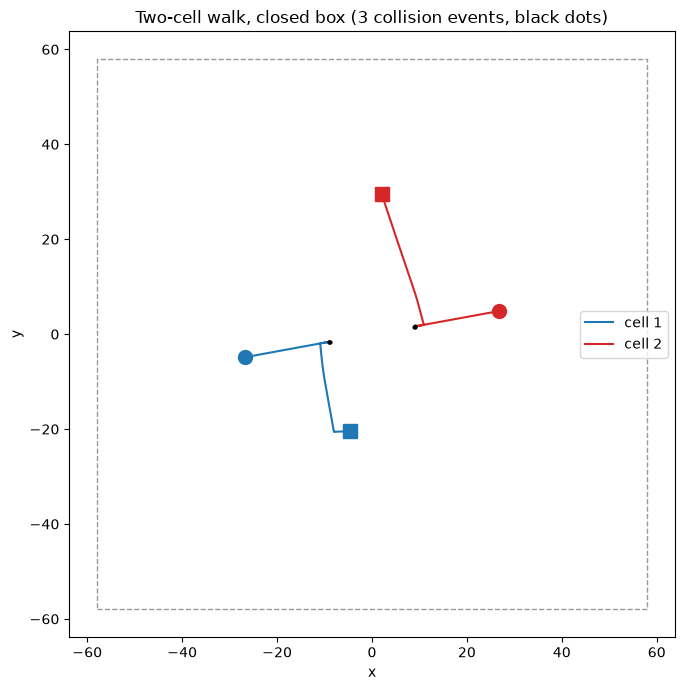

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(diag["x1"], diag["y1"], "-", color="tab:blue", lw=1.5, label="cell 1")
ax.plot(diag["x2"], diag["y2"], "-", color="tab:red", lw=1.5, label="cell 2")
ax.plot(diag["x1"][0], diag["y1"][0], "o", color="tab:blue", ms=10)
ax.plot(diag["x2"][0], diag["y2"][0], "o", color="tab:red", ms=10)
ax.plot(diag["x1"][-1], diag["y1"][-1], "s", color="tab:blue", ms=10)
ax.plot(diag["x2"][-1], diag["y2"][-1], "s", color="tab:red", ms=10)

collide_idx = np.where(diag["overlap"] > 1.5)[0]
if len(collide_idx):
    ax.plot(diag["x1"][collide_idx], diag["y1"][collide_idx], ".", color="black", ms=4)
    ax.plot(diag["x2"][collide_idx], diag["y2"][collide_idx], ".", color="black", ms=4)

box = L / 2 - 2
ax.plot([-box, box, box, -box, -box], [-box, -box, box, box, -box], "k--", lw=1, alpha=0.4)
ax.set_aspect("equal")
ax.set(xlabel="x", ylabel="y",
       title=f"Two-cell walk, closed box ({n_collisions} collision events, black dots)")
ax.legend()
plt.tight_layout()
plt.savefig("two_cell_walk_media/two_cell_walk_path.png", dpi=140)
plt.show()


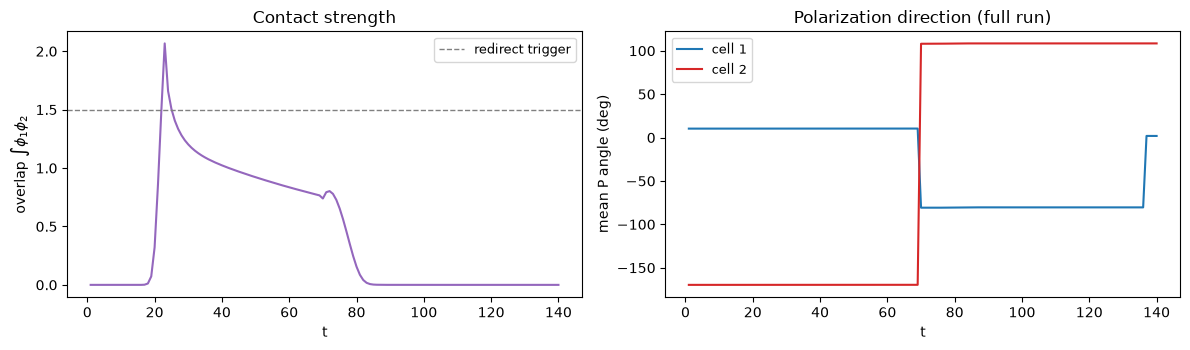

total collision events: 3
max overlap reached: 2.07  (natural non-interacting 'just touching' baseline is ~8.7)


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))

ax[0].plot(diag["time"], diag["overlap"], color="tab:purple")
ax[0].axhline(1.5, color="gray", ls="--", lw=1, label="redirect trigger")
ax[0].set(xlabel="t", ylabel=r"overlap $\int\phi_1\phi_2$", title="Contact strength")
ax[0].legend(fontsize=9)

ax[1].plot(diag["time"], diag["angle1_deg"], color="tab:blue", label="cell 1")
ax[1].plot(diag["time"], diag["angle2_deg"], color="tab:red", label="cell 2")
ax[1].set(xlabel="t", ylabel="mean P angle (deg)",
          title="Polarization direction (full run)")
ax[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("two_cell_walk_media/two_cell_walk_diagnostics.png", dpi=140)
plt.show()

print(f"total collision events: {n_collisions}")
print(f"max overlap reached: {diag['overlap'].max():.2f}  "
      f"(natural non-interacting 'just touching' baseline is ~8.7)")


### A controlled check: is the rotation actually physical?

In the run above, the big jumps in polarization angle are mostly the
*decision layer* instantly picking a new random heading — that
dwarfs the much smaller effect we actually want to isolate: does
contact torque the polarization *through the shared flow*, with
nothing telling it to? Here is a clean, controlled version with no
decision layer at all: two cells, fixed opposite headings, forced to
collide head-on. If the shared-Stokes coupling is doing real physical
work, both angles should sit flat until contact, then rotate
*symmetrically, in opposite senses*, the moment overlap turns on.


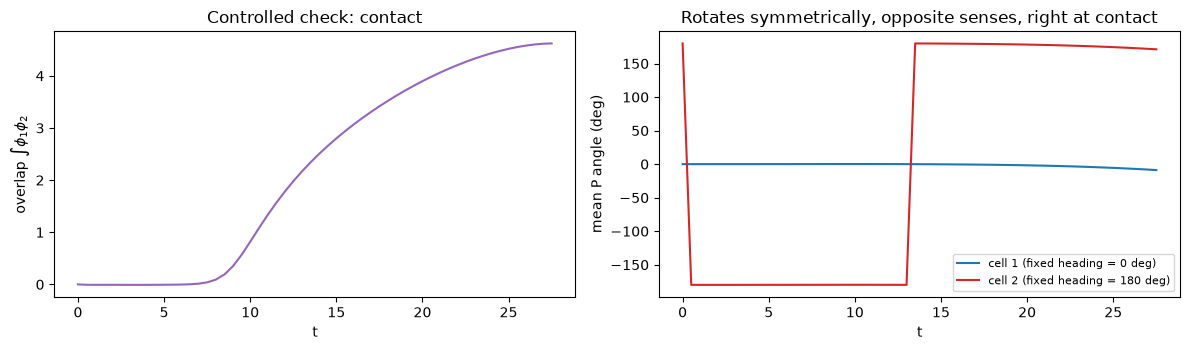

contact onset at t ~ 8.0
cell 1 angle: -0.00 deg -> -8.81 deg
cell 2 angle: +180.00 deg -> +171.19 deg (should move the same amount, opposite sign, as cell 1)


In [10]:
def mean_angle(phi, Px, Py):
    mx = (phi * Px).sum() / phi.sum()
    my = (phi * Py).sum() / phi.sum()
    return np.degrees(np.arctan2(my, mx))


phi1c, Px1c, Py1c = init_cell(-20.0, -3.0)
phi2c, Px2c, Py2c = init_cell(20.0, 3.0)
mask1c, mask2c = phi1c > 1e-3, phi2c > 1e-3
Px1c[mask1c] = 1.0    # fixed heading: straight at cell 2
Px2c[mask2c] = -1.0   # fixed heading: straight at cell 1

check_t, check_a1, check_a2, check_ov = [], [], [], []
for cstep in range(2800):
    phi1c, Px1c, Py1c, phi2c, Px2c, Py2c, _, _ = step_both(
        phi1c, Px1c, Py1c, phi2c, Px2c, Py2c, MOVE, MOVE)
    if cstep % 50 == 0:
        check_t.append(cstep * dt)
        check_a1.append(mean_angle(phi1c, Px1c, Py1c))
        check_a2.append(mean_angle(phi2c, Px2c, Py2c))
        check_ov.append((phi1c * phi2c).sum() * dx * dx)

check_t, check_a1, check_a2, check_ov = map(np.array, (check_t, check_a1, check_a2, check_ov))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(check_t, check_ov, color="tab:purple")
ax[0].set(xlabel="t", ylabel=r"overlap $\int\phi_1\phi_2$", title="Controlled check: contact")
ax[1].plot(check_t, check_a1, color="tab:blue", label="cell 1 (fixed heading = 0 deg)")
ax[1].plot(check_t, check_a2, color="tab:red", label="cell 2 (fixed heading = 180 deg)")
ax[1].set(xlabel="t", ylabel="mean P angle (deg)",
          title="Rotates symmetrically, opposite senses, right at contact")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("two_cell_walk_media/two_cell_walk_rotation_check.png", dpi=140)
plt.show()

onset = check_t[check_ov > 0.05][0] if (check_ov > 0.05).any() else None
print(f"contact onset at t ~ {onset}")
print(f"cell 1 angle: {check_a1[0]:+.2f} deg -> {check_a1[-1]:+.2f} deg")
print(f"cell 2 angle: {check_a2[0]:+.2f} deg -> {check_a2[-1]:+.2f} deg "
      f"(should move the same amount, opposite sign, as cell 1)")


# 7. A video of the walk

In [11]:
def composite_rgb(phi1, phi2):
    absorb1 = np.array([0.77, 0.52, 0.17])  # complement of tab:blue
    absorb2 = np.array([0.17, 0.67, 0.77])  # complement of tab:red
    img = (1.0 - np.clip(phi1, 0, 1)[..., None] * absorb1
               - np.clip(phi2, 0, 1)[..., None] * absorb2)
    return np.clip(img, 0, 1)


fig, ax = plt.subplots(figsize=(6.6, 6.6))


def render(i):
    ax.clear()
    t, f1, f2, ph1, ph2 = frames[i]
    img = composite_rgb(f1, f2)
    ax.imshow(img.transpose(1, 0, 2), origin="lower",
              extent=[-L / 2, L / 2, -L / 2, L / 2])
    box = L / 2 - wall_margin
    ax.plot([-box, box, box, -box, -box], [-box, -box, box, box, -box],
            "--", color="gray", lw=1, alpha=0.6)
    ax.set_title(f"t = {t:5.1f}   cell 1: {ph1}   cell 2: {ph2}")
    ax.set_xlim(-L / 2, L / 2)
    ax.set_ylim(-L / 2, L / 2)


render(0)
fig.tight_layout()


def update(i):
    render(i)
    return []


ani = animation.FuncAnimation(fig, update, frames=len(frames), blit=False)
fps = max(1, round(len(frames) / 6.0))
video_path = "two_cell_walk_media/two_cell_walk.mp4"
ani.save(video_path, writer=animation.FFMpegWriter(fps=fps, bitrate=2400))
plt.close(fig)

print(f"saved {video_path}: {len(frames)} frames at {fps} fps "
      f"= {len(frames) / fps:.1f} s")


saved two_cell_walk.mp4: 46 frames at 8 fps = 5.8 s


In [12]:
Video(video_path, embed=True, width=480)


# 8. What this does and doesn't claim

- **No merging, confirmed, not assumed.** The maximum overlap reached
  (printed in Section 6) should stay well under the $\approx8.7$ a
  non-interacting pair would show at exactly nominal contact — check
  that number on your run; if it is climbing toward that baseline
  instead of turning over, $k_{\rm rep}$ needs to go up.
- **Momentum and rotation are exchanged, not conserved in the strict
  Newtonian sense.** This is a system with substrate friction ($\xi$):
  the substrate is a real momentum sink/source, exactly as it is for a
  real crawling cell pushing against a surface, so the *total*
  momentum of the two-cell system is not conserved in the lab frame —
  nor should it be. What *is* physically principled is that the
  interaction **between** the two cells, mediated by the one shared
  $\mathbf v$, is reciprocal by construction.
- **The soft wall is an approximation**, clearly not a literal no-slip
  boundary (see Section 2). It is adequate for keeping cells inside a
  region and redirecting them before they would otherwise escape, not
  for anything requiring an exact hydrodynamic wall condition.
- **The redirect-on-collision and redirect-near-wall triggers are a
  deliberately simple policy** (instant 90%-random reorientation),
  the same spirit as the single-cell notebook's decision layer, not a
  claim about how a real cell actually re-polarises after a bump.
